# 2. Previsión de clientes y escenarios A013

El objetivo es **demanda observada: matriculaciones menos automatriculaciones**. Las señales de stock no se convierten en demanda verdadera; la alternativa reconstruida sólo se utiliza como sensibilidad. Se mantiene la estructura mercado del segmento × relación comercial de Kaido, cuyo numerador son clientes y cuyo denominador son matriculaciones de mercado: no es una cuota homogénea.

Se selecciona con A009–A011, desde los orígenes 96, 108 y 120; A012 se presenta aparte como evaluación retrospectiva, ya conocida durante la revisión del proyecto. El ajuste final utiliza legítimamente todo A012 para A013. Fuentes: CSV de `../data`, API de `notebooks/datos.ipynb` y decisiones D5–D11 de `docs/plan-revision-modelo.md`.

## API independiente

La celda `api` contiene únicamente imports, constantes y funciones. `preparar_prevision_revision()` carga mediante JSON y `exec` las celdas API de `datos.ipynb` en un espacio aislado, sin ejecutar sus gráficos ni exportaciones. Los argumentos `datos`, `serie` y `adelantos` permiten contrastar fixtures sin introducir una segunda implementación de la preparación de datos.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

SEGMENTOS = ["B", "C", "MD", "SSUV", "CSUV", "MSUV", "S"]
VALIDABLES = [s for s in SEGMENTOS if s != "CSUV"]
ORIGENES_SELECCION = [96, 108, 120]
MODELOS = ["estacional", "conf_sin_intercepto", "conf_intercepto", "macro"]
EVENTOS = ["incentivo_publico", "adelanto_compras", "caida_tras_adelanto", "subida_iva"]
MACRO = ["confianza_consumidor", "paro", "tipo_credito_consumo"]


def _leer_api_datos(ruta="datos.ipynb"):
    """Ejecuta exclusivamente la API de datos en un espacio independiente."""
    espacio = {"__name__": "api_datos_revision"}
    cuaderno = json.loads(Path(ruta).read_text(encoding="utf-8"))
    for celda in cuaderno["cells"]:
        if celda["cell_type"] == "code" and "api" in celda.get("metadata", {}).get("tags", []):
            exec(compile("".join(celda["source"]), str(ruta), "exec"), espacio)
    return espacio["preparar_datos_revision"]()


def _pivotar(serie, columna):
    return serie.pivot(index="t", columns="segmento", values=columna).reindex(columns=SEGMENTOS).sort_index()


def _mercado_completo(datos):
    return datos["mercado"].groupby(["t", "segmento"], observed=True)["unidades"].sum().unstack().reindex(columns=SEGMENTOS).sort_index()


def _calendario(datos):
    return pd.concat([datos["economia"], datos["calendario"]], ignore_index=True).drop_duplicates("t").set_index("t").sort_index()


def _valor_macro(cal, variable, t, origen, condicionado=False, trayectoria=None):
    # El límite se impone incluso si el fichero contiene valores futuros reales.
    fuente = t - 3
    if fuente > origen and trayectoria is not None:
        return float(pd.Series(trayectoria).iloc[min(fuente - origen - 1, 11)])
    limite = fuente if condicionado else min(fuente, origen)
    conocidos = cal.loc[cal.index <= limite, variable].dropna()
    return float(conocidos.iloc[-1]) if len(conocidos) else np.nan


def _fila_diseno(cal, t, origen, modelo, condicionado=False, cambios=None):
    cambios = cambios or {}
    fila = {}
    if modelo in ["conf_intercepto", "macro"]:
        fila["intercepto"] = 1.0
    for variable in ["dias_laborables", "semana_santa", *EVENTOS]:
        def valor(mes):
            if mes > origen and variable in cambios:
                return float(cambios[variable][mes - origen - 1])
            if mes > origen and variable in EVENTOS and not condicionado:
                return 0.0
            return float(cal.loc[mes, variable])
        actual, anterior = valor(t), valor(t - 12)
        fila[variable] = np.log(actual / anterior) if variable == "dias_laborables" else actual - anterior
    variables = MACRO if modelo == "macro" else ["confianza_consumidor"]
    for variable in variables:
        fila[variable] = _valor_macro(cal, variable, t, origen, condicionado, cambios.get(variable)) - _valor_macro(cal, variable, t - 12, origen, condicionado)
    return fila


def _ajustar_mercado(mercado, cal, origen, modelo):
    filas = []
    for t in range(16, origen + 1):
        fila = _fila_diseno(cal, t, origen, modelo)
        for segmento in SEGMENTOS:
            base, actual = mercado.loc[t - 12, segmento], mercado.loc[t, segmento]
            if base >= 200 and actual > 0:
                filas.append(dict(fila, y=np.log(actual / base), peso=np.sqrt(base)))
    tabla = pd.DataFrame(filas).dropna()
    columnas = [c for c in tabla if c not in ["y", "peso"] and tabla[c].abs().sum() > 0]
    x, y = tabla[columnas].to_numpy(), tabla["y"].to_numpy()
    raiz_peso = np.sqrt(tabla["peso"].to_numpy())
    beta = np.linalg.lstsq(x * raiz_peso[:, None], y * raiz_peso, rcond=None)[0]
    return pd.Series(beta, index=columnas)


def _prever_mercado(mercado, cal, origen, modelo, condicionado=False, cambios=None):
    indices = pd.RangeIndex(origen + 1, origen + 13, name="t")
    if modelo == "estacional":
        salida = mercado.loc[origen - 11:origen].copy()
        salida.index = indices
        return salida, pd.Series(dtype=float)
    beta = _ajustar_mercado(mercado, cal, origen, modelo)
    salida = pd.DataFrame(index=indices, columns=SEGMENTOS, dtype=float)
    for t in indices:
        fila = _fila_diseno(cal, t, origen, modelo, condicionado, cambios)
        crecimiento = float(beta @ pd.Series(fila).reindex(beta.index))
        salida.loc[t] = mercado.loc[t - 12] * np.exp(crecimiento)
    if not np.isfinite(salida.to_numpy()).all():
        raise ValueError("Previsión de mercado no finita; revisar entradas y ajuste.")
    return salida, beta


def _producto(serie, origen):
    """Contraste no causal, ventanas completas 6+6 y sin episodios solapados."""
    episodios = []
    historia = serie[serie["t"].le(origen)].copy()
    for segmento in SEGMENTOS:
        parte = historia[historia["segmento"].eq(segmento)].set_index("t").sort_index()
        fechas = parte.index[parte["renovacion_gama"].eq(1)]
        # Un flag consecutivo es un único episodio; otras renovaciones contaminan.
        inicios = [t for t in fechas if t - 1 not in fechas]
        for t in inicios:
            if t + 5 > origen:
                continue
            antes = parte.reindex(range(t - 6, t))
            despues = parte.reindex(range(t, t + 6))
            limpio = True
            for ventana in [antes, despues]:
                if ventana["demanda_observada"].isna().any() or ventana["mercado"].le(0).any():
                    limpio = False
                for c in EVENTOS + ["senal_falta_stock"]:
                    if c in ventana and ventana[c].fillna(0).gt(0).any():
                        limpio = False
            if any(t - 11 <= otro <= t + 5 and otro != t for otro in inicios):
                limpio = False
            # El lanzamiento no es una renovación estimable con ventas anteriores.
            if antes["demanda_observada"].sum() <= 0:
                limpio = False
            if limpio:
                ratio_antes = antes["demanda_observada"].sum() / antes["mercado"].sum()
                ratio_despues = despues["demanda_observada"].sum() / despues["mercado"].sum()
                episodios.append({"segmento": segmento, "t": t, "efecto": ratio_despues / ratio_antes - 1})
    episodios = pd.DataFrame(episodios, columns=["segmento", "t", "efecto"])
    positivos = episodios.loc[episodios["efecto"].gt(0), "efecto"]
    proxy_alto = float(positivos.quantile(.75)) if len(positivos) else 0.0
    filas = []
    for segmento in SEGMENTOS:
        efectos = episodios.loc[episodios["segmento"].eq(segmento), "efecto"]
        mediana = float(efectos.median()) if len(efectos) else np.nan
        alto_propio = max(0.0, float(efectos.quantile(.75))) if len(efectos) else 0.0
        alto = alto_propio if alto_propio > 0 else proxy_alto
        filas.append({"segmento": segmento, "n_episodios": len(efectos), "mediana_empirica": mediana,
                      "efecto_central": 0.0, "efecto_alto": alto, "efecto_alto_propio": alto_propio,
                      "fuente_alto": "P75 propio" if alto_propio > 0 else "P75 episodios positivos de otros segmentos: sensibilidad, no evidencia propia",
                      "inicio_a013": 145 if segmento in ["B", "SSUV", "CSUV", "MSUV"] else np.nan,
                      "duracion_meses": 6, "justificacion": "Antes/después no identifica causalidad; central neutro y sensibilidad empírica"})
    return pd.DataFrame(filas), episodios


def _exposicion(parte, efecto):
    """Retira el efecto supuesto ya presente en el ancla, para no duplicarlo."""
    fechas = parte.loc[parte["renovacion_gama"].eq(1), "t"].tolist()
    fechas = [t for t in fechas if t - 1 not in fechas]
    # No normalizar la madurez de CSUV como si fuese una renovación previa.
    if len(parte) and parte["segmento"].iloc[0] == "CSUV":
        return pd.Series(1.0, index=parte.index)
    expuesto = parte["t"].map(lambda t: any(f <= t < f + 6 for f in fechas))
    return 1 + efecto * expuesto.astype(float)


def _cuotas(serie, origen, columna="demanda_observada", adelantos=None, efectos=None):
    historia = serie[serie["t"].le(origen)].copy()
    filas = []
    for segmento in SEGMENTOS:
        todo = historia[historia["segmento"].eq(segmento)].copy()
        parte = todo[todo["t"].gt(origen - 12)].copy()
        if segmento == "CSUV":
            activos = todo[todo["demanda_observada"].gt(0)]
            parte = activos.iloc[1:].copy()  # agosto parcial; nunca ceros prelaunch
            parte["objetivo"] = parte[columna].astype(float)
            if adelantos is not None and len(parte):
                ledger = adelantos[adelantos["anio"].eq(f"A{(origen - 1) // 12 + 1:03d}") & adelantos["segmento"].eq(segmento)]
                cantidad = float(ledger["adelanto_central"].sum())
                marcas = parte["adelanto_compras"].eq(1)
                total = parte.loc[marcas, "objetivo"].sum()
                if total > 0:
                    parte.loc[marcas, "objetivo"] *= max(0.0, 1 - cantidad / total)
        else:
            limpio = ~parte[EVENTOS].fillna(0).gt(0).any(axis=1)
            parte = parte[limpio].copy()
            parte["objetivo"] = parte[columna].astype(float)
        if efectos is not None:
            exposicion = _exposicion(todo, float(efectos.get(segmento, 0)))
            parte["objetivo"] /= exposicion.reindex(parte.index)
        cuota = parte["objetivo"].sum() / parte["mercado"].sum() if parte["mercado"].sum() > 0 else 0.0
        filas.append({"segmento": segmento, "cuota": cuota, "meses": len(parte), "t_min": parte["t"].min(), "t_max": parte["t"].max()})
    return pd.DataFrame(filas).set_index("segmento")


def _prever(serie, mercado, cal, origen, modelo, condicionado=False, columna="demanda_observada", adelantos=None):
    mercado_prev, beta = _prever_mercado(mercado, cal, origen, modelo, condicionado)
    cuotas = _cuotas(serie, origen, columna, adelantos)
    if modelo == "estacional":
        historia = serie[serie["t"].le(origen)].copy()
        # Los ajustes de la API se identifican por episodio/año completo. Una
        # revisión dentro del año no debe usar su estimación calculada al cierre.
        cerrado = ((historia["t"] - 1) // 12 + 1) * 12 <= origen
        historia["ancla_normalizada"] = historia[columna].astype(float)
        for ajuste, signo in [("ajuste_adelanto_mes", -1), ("ajuste_caida_mes", 1)]:
            if ajuste in historia:
                historia.loc[cerrado, "ancla_normalizada"] += signo * historia.loc[cerrado, ajuste]
        historia["ancla_normalizada"] = historia["ancla_normalizada"].clip(lower=0)
        pred = _pivotar(historia, "ancla_normalizada").loc[origen - 11:origen].copy()
        pred.index = mercado_prev.index
    else:
        pred = mercado_prev * cuotas["cuota"]
    # CSUV se proyecta en los doce meses, no replicando los ceros prelaunch.
    pred["CSUV"] = mercado_prev["CSUV"] * cuotas.loc["CSUV", "cuota"]
    return pred, mercado_prev, cuotas, beta


def _registros(pred, observado, origen, modelo, fase):
    filas = []
    for t in pred.index:
        for segmento in VALIDABLES:
            p, o = float(pred.loc[t, segmento]), float(observado.loc[t, segmento])
            filas.append({"origen": origen, "anio": f"A{(t - 1) // 12 + 1:03d}", "t": t,
                          "segmento": segmento, "modelo": modelo, "fase": fase,
                          "observado": o, "prevision": p, "error": p - o,
                          "error_log": np.log((o + .5) / (p + .5))})
    return filas


def _metricas(errores):
    filas = []
    for (modelo, origen, fase), grupo in errores.groupby(["modelo", "origen", "fase"]):
        partes = [(s, grupo[grupo["segmento"].eq(s)]) for s in VALIDABLES]
        total = grupo.groupby("t")[["observado", "prevision", "error"]].sum()
        partes.append(("Total_sin_CSUV", total))
        for segmento, g in partes:
            denominador = g["observado"].sum()
            filas.append({"modelo": modelo, "origen": origen, "anio": f"A{origen // 12 + 1:03d}",
                          "fase": fase, "segmento": segmento, "mae": g["error"].abs().mean(),
                          "sesgo": g["error"].mean(), "mae_pct": g["error"].abs().sum() / denominador if denominador else np.nan})
    return pd.DataFrame(filas)


def _errores_tres_meses(errores):
    filas = []
    for (origen, fase), grupo in errores.groupby(["origen", "fase"]):
        partes = [(s, grupo[grupo["segmento"].eq(s)].set_index("t")) for s in VALIDABLES]
        partes.append(("Total_sin_CSUV", grupo.groupby("t")[["observado", "prevision", "error"]].sum()))
        for segmento, g in partes:
            g = g.sort_index()
            for i in range(len(g) - 2):
                ventana = g.iloc[i:i + 3]
                if ventana.index[-1] - ventana.index[0] != 2:
                    continue
                previsto, observado = ventana["prevision"].sum(), ventana["observado"].sum()
                filas.append({"origen": origen, "fase": fase, "segmento": segmento,
                              "t_inicio": ventana.index[0], "t_fin": ventana.index[-1],
                              "observado": observado, "prevision": previsto,
                              "error": previsto - observado, "error_rel_prevision": (previsto - observado) / previsto if previsto > 0 else np.nan})
    return pd.DataFrame(filas)


def _factores_sesgo(anteriores):
    factores = pd.Series(1.0, index=SEGMENTOS)
    for segmento in VALIDABLES:
        g = anteriores[anteriores["segmento"].eq(segmento)]
        folds = g.groupby("origen").agg(error=("error", "sum"), observado=("observado", "sum"), prevision=("prevision", "sum")).tail(2)
        if len(folds) == 2 and (folds["error"].gt(0).all() or folds["error"].lt(0).all()):
            factores[segmento] = float(np.clip(folds["observado"].sum() / folds["prevision"].sum(), .8, 1.2))
    return factores


def _diagnostico_sesgo(errores):
    """El factor de A011 se fija con A009/A010; A012 no decide la corrección."""
    anteriores = errores[errores["origen"].lt(120)]
    factores_prueba = _factores_sesgo(anteriores)
    factores_recientes = _factores_sesgo(errores[errores["origen"].le(120)])
    filas, factores = [], pd.Series(1.0, index=SEGMENTOS)
    for segmento in VALIDABLES:
        g = errores[errores["origen"].eq(120) & errores["segmento"].eq(segmento)]
        bruto = g["error"].abs().mean()
        corregido = (g["prevision"] * factores_prueba[segmento] - g["observado"]).abs().mean()
        aceptar = factores_prueba[segmento] != 1 and corregido < bruto and factores_recientes[segmento] != 1
        # Se conserva el factor verificado, no se reajusta con el fold verificador.
        if aceptar:
            factores[segmento] = factores_prueba[segmento]
        filas.append({"segmento": segmento, "factor_estimado_A009_A010": factores_prueba[segmento], "mae_A011_bruto": bruto,
                      "mae_A011_corregido": corregido, "factor_A013": factores[segmento], "aplicar": aceptar,
                      "fase": "Estimación A009/A010; verificación A011; A012 excluido"})
    return pd.DataFrame(filas), factores


def _incertidumbre(errores, ampliacion=1.5):
    sigmas, sd, pares_x, pares_y = {}, {}, [], []
    for segmento in VALIDABLES:
        ventanas, logs = [], []
        for _, g in errores[errores["segmento"].eq(segmento)].groupby("origen"):
            g = g.sort_values("t")
            logs.extend(g["error_log"].tolist())
            centrado = g["error_log"] - g["error_log"].mean()
            escala = centrado.std()
            if escala > 0:
                pares_x.extend((centrado.iloc[:-1] / escala).tolist())
                pares_y.extend((centrado.iloc[1:] / escala).tolist())
            for i in range(len(g) - 2):
                ventana = g.iloc[i:i + 3]
                if ventana["prevision"].sum() > 0:
                    ventanas.append(ventana["error"].sum() / ventana["prevision"].sum())
        sigmas[segmento] = float(np.std(ventanas, ddof=1))
        sd[segmento] = float(np.std(logs, ddof=1))
    sigma, sd = pd.Series(sigmas), pd.Series(sd)
    sigma["CSUV"] = ampliacion * sigma[["SSUV", "MSUV"]].mean()
    sd["CSUV"] = ampliacion * sd[["SSUV", "MSUV"]].mean()
    # Sólo parejas consecutivas dentro del mismo año/fold; no cruzar fronteras.
    phi = float(np.clip(np.corrcoef(pares_x, pares_y)[0, 1], -.8, .8))
    # Correlaciones dentro de fold, centradas por fold y segmento.
    correlaciones = []
    for _, g in errores.groupby("origen"):
        corr = g.pivot(index="t", columns="segmento", values="error_log").corr().to_numpy()
        correlaciones.extend(corr[np.triu_indices(len(VALIDABLES), 1)].tolist())
    rho_bruto = float(np.nanmean(correlaciones))
    rho = float(np.clip(rho_bruto, 0, .8))
    return sigma.reindex(SEGMENTOS), sd.reindex(SEGMENTOS), phi, rho, rho_bruto


def _turismo(datos):
    alquiler = datos["mercado"][datos["mercado"]["canal"].eq("ALQUILADORES")].pivot(index="t", columns="segmento", values="unidades")
    eco = datos["economia"].set_index("t")
    x = eco["viajeros_var"].diff(12)
    ventas = datos["ventas"].copy()
    ventas["clientes"] = ventas["unidades"] - ventas["u_automatriculacion"]
    ultimos = ventas[ventas["t"].between(121, 144)]
    total = ultimos.groupby("segmento", observed=True)["clientes"].sum()
    alquiladores = ultimos[ultimos["canal"].eq("ALQUILADORES")].groupby("segmento", observed=True)["clientes"].sum()
    filas = []
    for segmento in SEGMENTOS:
        y = np.log(alquiler[segmento].where(alquiler[segmento].gt(0))).diff(12)
        valido = pd.DataFrame({"x": x, "y": y}).dropna()
        diseno = np.column_stack([np.ones(len(valido)), valido["x"]])
        coef = float(np.linalg.lstsq(diseno, valido["y"], rcond=None)[0][1])
        filas.append({"segmento": segmento, "coef_viajeros": coef,
                      "peso_alquiladores_kaido": float(alquiladores.get(segmento, 0) / total[segmento]) if total[segmento] else 0.0})
    cambios = eco["viajeros_var"].diff(9).dropna()
    return pd.DataFrame(filas).set_index("segmento"), float(cambios.quantile(.1)), float(cambios.quantile(.9))


def _descontar_ledger(prevision, adelantos, meses, columna="adelanto_central"):
    salida = prevision.copy()
    filas = []
    for segmento in SEGMENTOS:
        cantidad = float(adelantos.set_index("segmento").loc[segmento, columna])
        antes = salida.loc[145:144 + meses, segmento].sum()
        salida.loc[145:144 + meses, segmento] = (salida.loc[145:144 + meses, segmento] - cantidad / meses).clip(lower=0)
        aplicado = antes - salida.loc[145:144 + meses, segmento].sum()
        filas.append({"segmento": segmento, "meses": meses, "solicitado": cantidad,
                      "aplicado": aplicado, "no_aplicado": max(0.0, cantidad - aplicado)})
    tabla = pd.DataFrame(filas)
    salida.attrs["ledger_adelantos"] = {"solicitado": float(tabla["solicitado"].sum()), "aplicado": float(tabla["aplicado"].sum()),
                                       "no_aplicado_por_no_negatividad": float(tabla["no_aplicado"].sum())}
    return salida, tabla


def preparar_prevision_revision(datos=None, serie=None, adelantos=None, ruta_datos="datos.ipynb"):
    """Previsión de clientes netos. Sin argumentos carga la API de datos aislada."""
    if datos is None and serie is None:
        revision = _leer_api_datos(ruta_datos)
        datos, serie, adelantos = revision["datos"], revision["serie"], revision["adelantos"]
    elif datos is None or serie is None:
        raise ValueError("Para fixture deben aportarse datos y serie juntos.")
    if adelantos is None:
        adelantos = datos.get("adelantos")
    if adelantos is None:
        raise ValueError("El fixture debe aportar el ledger de adelantos explícitamente.")
    observado = _pivotar(serie, "demanda_observada")
    mercado, cal = _mercado_completo(datos), _calendario(datos)
    assert mercado.index.min() == 1, "Se requiere mercado completo desde A001."
    registros = []
    for origen in ORIGENES_SELECCION:
        for modelo in MODELOS:
            pred, _, _, _ = _prever(serie, mercado, cal, origen, modelo)
            registros.extend(_registros(pred, observado, origen, modelo, "seleccion_operativa"))
    todos = pd.DataFrame(registros)
    seleccion = todos.groupby("modelo").agg(error_absoluto=("error", lambda x: x.abs().sum()), observado=("observado", "sum"))
    seleccion["wape"] = seleccion["error_absoluto"] / seleccion["observado"]
    # En empate prevalece la referencia más sencilla; no participa A012.
    seleccionado = min(MODELOS, key=lambda m: (seleccion.loc[m, "wape"], MODELOS.index(m)))
    bruto = todos[todos["modelo"].eq(seleccionado)].copy()
    sesgo, factores = _diagnostico_sesgo(bruto)
    errores_calibracion = bruto.copy()
    # Corrección prospectiva predefinida para A011, sin condicionar al éxito del fold.
    f_prueba = _factores_sesgo(bruto[bruto["origen"].lt(120)])
    prueba = bruto[bruto["origen"].eq(120)].copy()
    prueba["prevision"] *= prueba["segmento"].map(f_prueba)
    prueba["error"] = prueba["prevision"] - prueba["observado"]
    prueba["error_log"] = np.log((prueba["observado"] + .5) / (prueba["prevision"] + .5))
    prueba["fase"] = "sesgo_OOF_A011"
    # Calibración conservadora con errores sin selección posterior de correcciones.
    pred_a012, _, _, _ = _prever(serie, mercado, cal, 132, seleccionado)
    pred_a012 *= factores
    registros.extend(_registros(pred_a012, observado, 132, seleccionado, "retrospectiva_A012"))
    condicionadas = []
    for origen in [*ORIGENES_SELECCION, 132]:
        for modelo in MODELOS[1:]:
            pred, _, _, _ = _prever(serie, mercado, cal, origen, modelo, condicionado=True)
            condicionadas.extend(_registros(pred, observado, origen, modelo, "condicionada_economia_eventos_reales"))
    todos_metricas = pd.concat([pd.DataFrame(registros), prueba, pd.DataFrame(condicionadas)], ignore_index=True)
    revisiones = []
    for origen in range(96, 144):
        pred, _, _, _ = _prever(serie, mercado, cal, origen, seleccionado)
        # La evidencia de A011 sólo está disponible desde su cierre, t=132.
        if origen >= 132:
            pred *= factores
        pred = pred.loc[origen + 1:min(origen + 3, 144)]
        revisiones.extend(_registros(pred, observado, origen, seleccionado, "revision_mensual_hasta_3_meses"))
    errores_revision = pd.DataFrame(revisiones)
    producto, episodios = _producto(serie, 144)
    ledger = adelantos[adelantos["anio"].eq("A012")].copy()
    if ledger["segmento"].duplicated().any() or set(ledger["segmento"]) != set(SEGMENTOS):
        raise ValueError("Ledger A012 debe tener exactamente una fila por segmento.")
    cantidades = ledger[["adelanto_min", "adelanto_central", "adelanto_max"]]
    if not np.isfinite(cantidades.to_numpy()).all() or cantidades.lt(0).any().any():
        raise ValueError("Ledger no finito o negativo.")
    if not (ledger["adelanto_min"].le(ledger["adelanto_central"]) & ledger["adelanto_central"].le(ledger["adelanto_max"])).all():
        raise ValueError("Ledger: mínimo, central y máximo deben estar ordenados.")
    if "saldo_para_siguiente_anio" in ledger and not np.allclose(ledger["adelanto_central"], ledger["saldo_para_siguiente_anio"]):
        raise ValueError("Ledger A012 no equivale al saldo transferido a A013.")
    previo, mercado_prev, cuotas, beta = _prever(serie, mercado, cal, 144, seleccionado, adelantos=adelantos)
    previo *= factores
    prevision, ledger_central = _descontar_ledger(previo, ledger, 3)
    sigma, sd, phi, rho, rho_bruto = _incertidumbre(errores_calibracion)
    turismo, turismo_bajo, turismo_alto = _turismo(datos)
    eco = datos["economia"].set_index("t").loc[:144]
    confianza_delta = eco["confianza_consumidor"].diff(9).dropna()
    credito_delta = float(eco["tipo_credito_consumo"].diff(9).abs().dropna().median())
    supuestos = {
        "pesimista": {"paro": 2.0, "confianza_consumidor": float(confianza_delta.quantile(.1)), "tipo_credito_consumo": credito_delta,
                      "turismo": turismo_bajo, "duracion_ledger": 6, "ayuda": 0.0},
        "central": {"paro": 0.0, "confianza_consumidor": 0.0, "tipo_credito_consumo": 0.0,
                    "turismo": 0.0, "duracion_ledger": 3, "ayuda": 0.0},
        "optimista": {"paro": -1.0, "confianza_consumidor": float(confianza_delta.quantile(.9)), "tipo_credito_consumo": -credito_delta,
                      "turismo": turismo_alto, "duracion_ledger": 1, "ayuda": 1.0},
    }
    filas_parametros = []
    for nombre, valores in supuestos.items():
        for factor, valor in valores.items():
            unidad = "meses" if factor == "duracion_ledger" else ("indicador abr-dic" if factor == "ayuda" else "puntos del indicador")
            razon = "Misma cantidad central del ledger en todos los escenarios" if factor == "duracion_ledger" else "Trayectoria congelada + choque explícito; relación histórica no causal"
            if factor in ["confianza_consumidor", "turismo"]:
                razon = "P10/P90 de cambios históricos a nueve meses; central sin cambio"
            if factor == "tipo_credito_consumo":
                razon = "Mediana absoluta del cambio histórico a nueve meses"
            filas_parametros.append(dict(escenario=nombre, factor=factor, valor=valor, unidad=unidad, justificacion=razon))
        for segmento in ["B", "SSUV", "CSUV", "MSUV"]:
            alto = float(producto.set_index("segmento").loc[segmento, "efecto_alto"])
            filas_parametros.append(dict(escenario=nombre, factor=f"producto_{segmento}", valor=alto if nombre == "optimista" else 0.0,
                                        unidad="variación ratio neto/mercado durante 6 meses", justificacion="Enero supuesto; MSUV pesimista abril; central neutro por identificación insuficiente"))
    csuv = serie[serie["segmento"].eq("CSUV") & serie["t"].between(141, 144)].copy()
    cantidad = float(ledger.set_index("segmento").loc["CSUV", "adelanto_central"])
    marcas = csuv["adelanto_compras"].eq(1)
    csuv["observado_ajustado"] = csuv["demanda_observada"].astype(float)
    if csuv.loc[marcas, "demanda_observada"].sum() > 0:
        csuv.loc[marcas, "observado_ajustado"] *= max(0, 1 - cantidad / csuv.loc[marcas, "demanda_observada"].sum())
    ratio_sep_oct = csuv.loc[csuv["t"].le(142), "demanda_observada"].sum() / csuv.loc[csuv["t"].le(142), "mercado"].sum()
    ratio_ajustado = csuv["observado_ajustado"].sum() / csuv["mercado"].sum()
    sens_csuv = pd.DataFrame([
        {"metodo": "sept-oct sin adelantos", "cuota": ratio_sep_oct, "demanda_anual_antes_ledger": mercado_prev["CSUV"].sum() * ratio_sep_oct},
        {"metodo": "sept-dic ajustados por ledger", "cuota": ratio_ajustado, "demanda_anual_antes_ledger": mercado_prev["CSUV"].sum() * ratio_ajustado},
    ])
    sens_proxy = pd.DataFrame({"multiplicador_proxy": [1.0, 1.5, 2.0],
                               "sd_log_csuv": [sd["CSUV"] * x / 1.5 for x in [1, 1.5, 2]],
                               "sigma3_csuv": [sigma["CSUV"] * x / 1.5 for x in [1, 1.5, 2]]})
    sens_stock = pd.DataFrame()
    if "demanda_alternativa" in serie:
        alternativa, _, _, _ = _prever(serie, mercado, cal, 144, seleccionado, columna="demanda_alternativa", adelantos=adelantos)
        alternativa *= factores
        alternativa, _ = _descontar_ledger(alternativa, ledger, 3)
        sens_stock = pd.DataFrame({"observada_anual": prevision.sum(), "alternativa_anual": alternativa.sum()})
        sens_stock["diferencia"] = sens_stock["alternativa_anual"] - sens_stock["observada_anual"]
    beta_aux = _ajustar_mercado(mercado, cal, 144, "macro")
    contexto = {"mercado": mercado, "calendario": cal, "previo_ledger": previo, "beta_aux": beta_aux,
                "supuestos": supuestos, "turismo": turismo, "factores_sesgo": factores, "serie": serie,
                "cuotas": cuotas, "adelantos_completos": adelantos}
    return {"datos": datos, "serie": serie, "prevision": prevision, "mercado_prevision": mercado_prev,
            "errores": errores_calibracion[["origen", "t", "segmento", "observado", "prevision", "error", "error_log"]],
            "sigma3_rel": sigma, "sd_log": sd, "phi": phi, "rho": rho, "rho_bruto": rho_bruto,
            "adelantos": ledger, "producto": producto, "episodios_producto": episodios,
            "modelo_elegido": seleccionado, "metricas": _metricas(todos_metricas), "seleccion": seleccion.reset_index(),
            "errores_todos": todos_metricas, "cuotas": cuotas["cuota"], "diagnostico_cuotas": cuotas,
            "parametros_escenarios": pd.DataFrame(filas_parametros), "sesgo": sesgo, "ledger_central": ledger_central,
            "errores_revisiones": errores_revision, "metricas_revisiones": _metricas(errores_revision),
            "errores_tres_meses": _errores_tres_meses(todos_metricas[todos_metricas["modelo"].eq(seleccionado) & todos_metricas["fase"].isin(["seleccion_operativa", "retrospectiva_A012"])]),
            "sensibilidad_stock": sens_stock, "diagnostico_csuv": csuv, "sensibilidad_csuv": sens_csuv,
            "sensibilidad_proxy_csuv": sens_proxy, "modelo_auxiliar": beta_aux,
            "modelo_escenarios": "Ratio de estrés macroeconómico auxiliar; no reestima el central", "_contexto": contexto}


def prever_escenario_revision(base, nombre, overrides=None):
    """Demanda 12×7. El central devuelve exactamente la base sin nuevos ajustes."""
    if nombre not in ["pesimista", "central", "optimista"]:
        raise ValueError("Escenario no reconocido.")
    if nombre == "central":
        if overrides == {"sin_ledger": True}:
            return base["_contexto"]["previo_ledger"].copy()
        if overrides:
            raise ValueError("Los overrides son sensibilidades de extremos; central es la base.")
        return base["prevision"].copy()
    overrides = overrides or {}
    contexto = base["_contexto"]
    supuestos = dict(contexto["supuestos"][nombre])
    supuestos.update(overrides.get("supuestos", {}))
    eco = contexto["calendario"].loc[:144]
    cambios = {variable: [float(eco[variable].dropna().iloc[-1]) + supuestos[variable]] * 12 for variable in MACRO}
    cambios["incentivo_publico"] = [0.0] * 3 + [supuestos["ayuda"]] * 9
    cambios.update(overrides.get("macroeconomia", {}))
    auxiliar_central, _ = _prever_mercado(contexto["mercado"], contexto["calendario"], 144, "macro")
    auxiliar_escenario, _ = _prever_mercado(contexto["mercado"], contexto["calendario"], 144, "macro", cambios=cambios)
    salida = contexto["previo_ledger"].copy()
    alto = base["producto"].set_index("segmento")["efecto_alto"]
    # El central no tiene incremento causal estimado. La sensibilidad optimista
    # normaliza la exposición histórica al mismo efecto hipotético antes de añadirlo.
    if nombre == "optimista":
        efectos = pd.Series(0.0, index=SEGMENTOS)
        nuevos = ["B", "SSUV", "CSUV", "MSUV"]
        efectos.loc[nuevos] = alto.loc[nuevos]
        efectos.update(pd.Series(overrides.get("producto", {}), dtype=float))
        if base["modelo_elegido"] == "estacional":
            for segmento in ["B", "SSUV", "MSUV"]:
                parte = contexto["serie"][contexto["serie"]["segmento"].eq(segmento) & contexto["serie"]["t"].le(144)]
                norm = _exposicion(parte, efectos[segmento])
                ancla = norm[parte["t"].between(133, 144)].to_numpy()
                salida[segmento] /= ancla
        else:
            cuotas_norm = _cuotas(contexto["serie"], 144, adelantos=contexto["adelantos_completos"], efectos=efectos)["cuota"]
            original = contexto["cuotas"]["cuota"].replace(0, np.nan)
            salida *= (cuotas_norm / original).fillna(1)
        for segmento in ["B", "SSUV", "CSUV", "MSUV"]:
            inicio = int(overrides.get("inicio_producto", {}).get(segmento, 145))
            salida.loc[inicio:inicio + 5, segmento] *= 1 + efectos[segmento]
    salida *= auxiliar_escenario / auxiliar_central
    # Temporada mar-jun: viajeros afecta sólo al canal alquiler de Kaido.
    turismo = contexto["turismo"]
    for segmento in SEGMENTOS:
        factor = np.exp(turismo.loc[segmento, "coef_viajeros"] * supuestos["turismo"] * turismo.loc[segmento, "peso_alquiladores_kaido"])
        salida.loc[147:150, segmento] *= factor
    if overrides.get("sin_ledger", False):
        return salida
    columna = overrides.get("ledger_columna", "adelanto_central")
    meses = int(overrides.get("duracion_ledger", supuestos["duracion_ledger"]))
    if meses not in range(1, 13) or columna not in ["adelanto_central", "adelanto_min", "adelanto_max"]:
        raise ValueError("Sensibilidad de ledger inválida.")
    salida, ledger = _descontar_ledger(salida, base["adelantos"], meses, columna)
    salida.attrs["detalle_ledger"] = ledger.to_dict("records")
    if not np.isfinite(salida.to_numpy()).all() or salida.lt(0).any().any():
        raise ValueError("Escenario con cantidades inválidas.")
    return salida


In [2]:
import os
import platform
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.style.use("../config/graficos.mplstyle")
SALIDA = Path(os.environ.get("SALIDA_DEMANDA", "../results/demanda"))
TABLAS, FIGURAS = SALIDA / "tablas", SALIDA / "figuras"
TABLAS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

def mostrar_tabla(tabla, nombre):
    salida = tabla.copy()
    if salida.index.name is not None or not isinstance(salida.index, pd.RangeIndex):
        salida = salida.reset_index()
    salida.to_csv(TABLAS / f"{nombre}.csv", index=False)
    display(tabla.round(4))

def guardar_figura(figura, nombre):
    for extension in ["png", "svg"]:
        figura.savefig(FIGURAS / f"{nombre}.{extension}", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

base = preparar_prevision_revision()
print(f"Python {platform.python_version()}, numpy {np.__version__}, pandas {pd.__version__}; semilla 42")


Python 3.13.15, numpy 2.5.3, pandas 3.0.6; semilla 42


## Selección temporal antes de A012

Se comparan cuatro candidatos: neto estacional; mercado WLS log-interanual con calendario, sucesos históricos y confianza a tres meses, sin y con intercepto; y la misma especificación con confianza, paro y crédito. La referencia normaliza el ancla de años cerrados con `observada − ajuste_adelanto_mes + ajuste_caida_mes`: elimina la repetición del pico histórico, sin confundirlo con la devolución A013 del ledger. Durante revisiones dentro del año no se utilizan sus ajustes estimados al cierre. Los pesos WLS son la raíz del mercado previo, con historia de mercado desde A001 y bases de al menos 200 coches para evitar ruido de segmentos recién aparecidos.

La selección global minimiza `SUM(abs(previsión−observado))/SUM(observado)` sobre los seis segmentos maduros y los 36 meses de A009–A011. Los sucesos futuros operativos son cero; la fuente económica es `min(t−3, origen)`, aunque el CSV incluya observaciones posteriores. El calendario laboral es conocido y no se confunde con economía futura.

In [3]:
mostrar_tabla(base["seleccion"].sort_values("wape"), "seleccion_a009_a011")
mostrar_tabla(base["metricas"].query("fase == 'seleccion_operativa'"), "metricas_seleccion_por_anio_segmento")
ganador = base["modelo_elegido"]
wape = base["seleccion"].set_index("modelo").loc[ganador, "wape"]
display(Markdown(f"Se elige **{ganador}**, con WAPE {wape:.1%} antes de A012. La referencia estacional se conserva si gana; los ratios económicos auxiliares de escenarios no reestiman el central. Este resultado mide error sobre clientes observados, no sobre demanda perdida ni precisión del lanzamiento CSUV."))


,modelo,error_absoluto,observado,wape
0,conf_intercepto,12569.6827,52881.0,0.2377
1,conf_sin_intercepto,12691.7899,52881.0,0.2400
3,macro,13106.1198,52881.0,0.2478
2,estacional,15894.0000,52881.0,0.3006


,modelo,origen,anio,fase,segmento,mae,sesgo,mae_pct
7,conf_intercepto,96,A009,seleccion_operativa,B,23.1181,5.9362,0.2141
8,conf_intercepto,96,A009,seleccion_operativa,C,23.9113,-10.9563,0.0991
9,conf_intercepto,96,A009,seleccion_operativa,MD,29.5186,12.0261,0.2138
10,conf_intercepto,96,A009,seleccion_operativa,SSUV,166.6878,-166.6878,0.4905
11,conf_intercepto,96,A009,seleccion_operativa,MSUV,88.9849,43.9385,0.1715
...,...,...,...,...,...,...,...,...
170,macro,120,A011,seleccion_operativa,MD,35.9237,32.5795,0.4243
171,macro,120,A011,seleccion_operativa,SSUV,70.1875,-40.0246,0.1679
172,macro,120,A011,seleccion_operativa,MSUV,108.2452,-104.7961,0.1566
173,macro,120,A011,seleccion_operativa,S,14.0538,11.7372,0.4064


Se elige **conf_intercepto**, con WAPE 23.8% antes de A012. La referencia estacional se conserva si gana; los ratios económicos auxiliares de escenarios no reestiman el central. Este resultado mide error sobre clientes observados, no sobre demanda perdida ni precisión del lanzamiento CSUV.

## Sesgo: parámetro anterior al fold verificador

Un factor por segmento se estima únicamente con A009/A010 si los dos sesgos anuales tienen el mismo signo; se limita a 0,8–1,2. Se aplica prospectivamente a A011 para contrastarlo y sólo se acepta para A012/A013 si mejora A011 y el signo continúa estable en los dos últimos folds de selección. El factor aceptado es el estimado antes de A011, no un reajuste con el año que lo verifica.

La calibración de incertidumbre conserva los errores brutos de los tres folds, sin elegir a posteriori cuáles corregir. La muestra reducida no demuestra ausencia de sesgo: se muestran los factores y la comparación independiente, y CSUV no recibe una corrección inferida de ceros anteriores al lanzamiento.

In [4]:
mostrar_tabla(base["sesgo"], "diagnostico_sesgo_oof")
mostrar_tabla(base["metricas"].query("fase == 'sesgo_OOF_A011'"), "verificacion_sesgo_a011")
aceptados = base["sesgo"].loc[base["sesgo"]["aplicar"], "segmento"].tolist()
display(Markdown(f"Se acepta la corrección para {', '.join(aceptados) if aceptados else 'ningún segmento'}. Los demás mantienen factor uno; no se fuerza una previsión sin sesgo. A012 no interviene en esta decisión ni en el parámetro de corrección."))


,segmento,factor_estimado_A009_A010,mae_A011_bruto,mae_A011_corregido,factor_A013,aplicar,fase
0,B,0.8845,46.1583,50.9572,1.0000,False,Estimación A009/A010; verificación A011; A012 ...
1,C,1.0892,65.8035,76.7439,1.0000,False,Estimación A009/A010; verificación A011; A012 ...
2,MD,0.8439,29.4817,19.8639,0.8439,True,Estimación A009/A010; verificación A011; A012 ...
3,SSUV,1.2000,75.9359,68.2926,1.2000,True,Estimación A009/A010; verificación A011; A012 ...
4,MSUV,1.0000,142.7098,142.7098,1.0000,False,Estimación A009/A010; verificación A011; A012 ...
5,S,1.2000,11.9427,17.5189,1.0000,False,Estimación A009/A010; verificación A011; A012 ...


,modelo,origen,anio,fase,segmento,mae,sesgo,mae_pct
42,conf_intercepto,120,A011,sesgo_OOF_A011,B,50.9572,-44.5612,0.4031
43,conf_intercepto,120,A011,sesgo_OOF_A011,C,76.7439,35.8236,0.2804
44,conf_intercepto,120,A011,sesgo_OOF_A011,MD,19.8639,7.6095,0.2346
45,conf_intercepto,120,A011,sesgo_OOF_A011,SSUV,68.2926,6.3826,0.1634
46,conf_intercepto,120,A011,sesgo_OOF_A011,MSUV,142.7098,-142.7098,0.2064
47,conf_intercepto,120,A011,sesgo_OOF_A011,S,17.5189,17.1723,0.5066
48,conf_intercepto,120,A011,sesgo_OOF_A011,Total_sin_CSUV,195.3865,-120.2830,0.1200


Se acepta la corrección para MD, SSUV. Los demás mantienen factor uno; no se fuerza una previsión sin sesgo. A012 no interviene en esta decisión ni en el parámetro de corrección.

## Evaluación retrospectiva A012 y condicionada

MAE y sesgo se expresan en coches por mes, con error = previsión − observado; `mae_pct` divide el error absoluto acumulado por las ventas netas observadas. En el total comparable se suman los seis segmentos **antes** de calcular error, evitando confundir cancelación de errores con acierto por segmento.

La evaluación condicionada utiliza la economía y los sucesos reales futuros y se etiqueta por separado: no representa lo que se habría sabido al cierre. Las revisiones mensuales se vuelven a ajustar con la historia disponible en cada mes y se evalúan a hasta tres meses, sin mezclarlas con el plan anual inicial.

In [5]:
mostrar_tabla(base["metricas"].query("fase == 'retrospectiva_A012'"), "evaluacion_retrospectiva_a012")
mostrar_tabla(base["metricas"].query("fase == 'condicionada_economia_eventos_reales'"), "evaluacion_condicionada")
mostrar_tabla(base["metricas_revisiones"], "metricas_revisiones_mensuales")
mostrar_tabla(base["errores_tres_meses"], "errores_acumulados_tres_meses")
base["errores"].to_csv(TABLAS / "errores_calibracion.csv", index=False)
base["errores_revisiones"].to_csv(TABLAS / "errores_revisiones_mensuales.csv", index=False)
ret = base["metricas"].query("fase == 'retrospectiva_A012' and segmento == 'Total_sin_CSUV'").iloc[0]
display(Markdown(f"En A012 el total comparable tiene MAE {ret.mae:.1f} coches/mes y sesgo {ret.sesgo:+.1f}, con error relativo {ret.mae_pct:.1%}. Es una evaluación retrospectiva, no un año nunca visto. El diagnóstico condicionado y las revisiones mensuales responden preguntas distintas y no sustituyen esta cifra."))


,modelo,origen,anio,fase,segmento,mae,sesgo,mae_pct
56,conf_intercepto,132,A012,retrospectiva_A012,B,45.6894,-40.3522,0.3378
57,conf_intercepto,132,A012,retrospectiva_A012,C,114.0760,-61.6898,0.3704
58,conf_intercepto,132,A012,retrospectiva_A012,MD,11.9672,8.0142,0.2430
59,conf_intercepto,132,A012,retrospectiva_A012,SSUV,82.9355,-69.9830,0.1766
60,conf_intercepto,132,A012,retrospectiva_A012,MSUV,115.9516,-18.5316,0.1860
61,conf_intercepto,132,A012,retrospectiva_A012,S,13.0441,-7.6212,0.3208
62,conf_intercepto,132,A012,retrospectiva_A012,Total_sin_CSUV,240.4763,-190.1636,0.1479


,modelo,origen,anio,fase,segmento,mae,sesgo,mae_pct
0,conf_intercepto,96,A009,condicionada_economia_eventos_reales,B,24.0067,-5.6096,0.2223
1,conf_intercepto,96,A009,condicionada_economia_eventos_reales,C,44.2747,-34.1227,0.1836
2,conf_intercepto,96,A009,condicionada_economia_eventos_reales,MD,21.1327,-3.5890,0.1530
3,conf_intercepto,96,A009,condicionada_economia_eventos_reales,SSUV,185.2011,-185.2011,0.5450
4,conf_intercepto,96,A009,condicionada_economia_eventos_reales,MSUV,57.0044,-15.7757,0.1099
...,...,...,...,...,...,...,...,...
177,macro,132,A012,condicionada_economia_eventos_reales,MD,32.2555,32.2555,0.6549
178,macro,132,A012,condicionada_economia_eventos_reales,SSUV,93.1898,-60.9319,0.1985
179,macro,132,A012,condicionada_economia_eventos_reales,MSUV,124.2196,118.6637,0.1993
180,macro,132,A012,condicionada_economia_eventos_reales,S,10.2288,-0.7680,0.2515


,modelo,origen,anio,fase,segmento,mae,sesgo,mae_pct
0,conf_intercepto,96,A009,revision_mensual_hasta_3_meses,B,41.0444,7.7220,0.3528
1,conf_intercepto,96,A009,revision_mensual_hasta_3_meses,C,40.2074,0.4006,0.1550
2,conf_intercepto,96,A009,revision_mensual_hasta_3_meses,MD,28.8423,-27.0860,0.1654
3,conf_intercepto,96,A009,revision_mensual_hasta_3_meses,SSUV,171.7092,-171.7092,0.5115
4,conf_intercepto,96,A009,revision_mensual_hasta_3_meses,MSUV,75.0350,-21.6222,0.1296
...,...,...,...,...,...,...,...,...
331,conf_intercepto,143,A012,revision_mensual_hasta_3_meses,MD,6.7021,6.7021,0.1971
332,conf_intercepto,143,A012,revision_mensual_hasta_3_meses,SSUV,90.0503,90.0503,0.2321
333,conf_intercepto,143,A012,revision_mensual_hasta_3_meses,MSUV,340.8619,-340.8619,0.3977
334,conf_intercepto,143,A012,revision_mensual_hasta_3_meses,S,16.7352,-16.7352,0.3719


,origen,fase,segmento,t_inicio,t_fin,observado,prevision,error,error_rel_prevision
0,96,seleccion_operativa,B,97,99,349.0,372.1659,23.1659,0.0622
1,96,seleccion_operativa,B,98,100,320.0,414.2124,94.2124,0.2274
2,96,seleccion_operativa,B,99,101,325.0,428.1996,103.1996,0.2410
3,96,seleccion_operativa,B,100,102,335.0,427.4229,92.4229,0.2162
4,96,seleccion_operativa,B,101,103,363.0,421.7491,58.7491,0.1393
...,...,...,...,...,...,...,...,...,...
275,132,retrospectiva_A012,Total_sin_CSUV,138,140,4572.0,4487.4558,-84.5442,-0.0188
276,132,retrospectiva_A012,Total_sin_CSUV,139,141,4168.0,3731.0988,-436.9012,-0.1171
277,132,retrospectiva_A012,Total_sin_CSUV,140,142,4245.0,3134.7792,-1110.2208,-0.3542
278,132,retrospectiva_A012,Total_sin_CSUV,141,143,5189.0,3534.7882,-1654.2118,-0.4680


En A012 el total comparable tiene MAE 240.5 coches/mes y sesgo -190.2, con error relativo 14.8%. Es una evaluación retrospectiva, no un año nunca visto. El diagnóstico condicionado y las revisiones mensuales responden preguntas distintas y no sustituyen esta cifra.

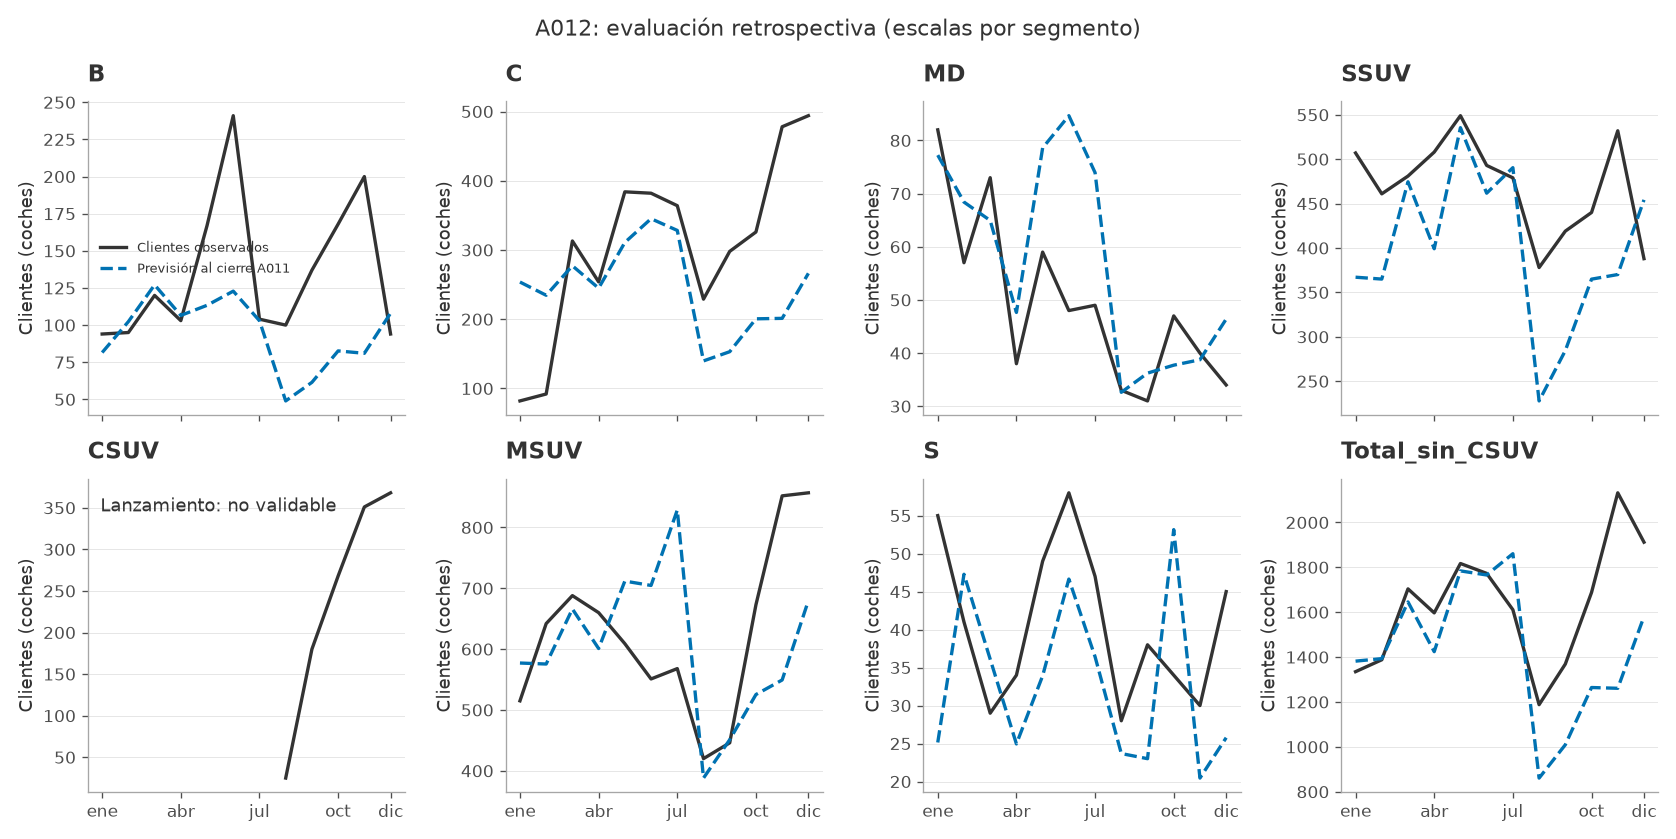

In [6]:
fig, ejes = plt.subplots(2, 4, figsize=(14, 7), sharex=True)
errores_a012 = base["errores_todos"].query("fase == 'retrospectiva_A012'")
for eje, segmento in zip(ejes.flat, SEGMENTOS + ["Total_sin_CSUV"]):
    if segmento == "CSUV":
        parte = base["serie"].query("segmento == 'CSUV' and t >= 140")
        eje.plot(parte["mes"], parte["demanda_observada"], color="#333333", label="Clientes observados")
        eje.text(.04, .94, "Lanzamiento: no validable", transform=eje.transAxes, va="top")
    else:
        g = errores_a012 if segmento == "Total_sin_CSUV" else errores_a012[errores_a012["segmento"].eq(segmento)]
        g = g.groupby("t")[["observado", "prevision"]].sum()
        eje.plot(g.index - 132, g["observado"], color="#333333", label="Clientes observados")
        eje.plot(g.index - 132, g["prevision"], color="#0072B2", linestyle="--", label="Previsión al cierre A011")
    eje.set_title(segmento, loc="left")
    eje.set_ylabel("Clientes (coches)")
    eje.set_xticks([1, 4, 7, 10, 12], ["ene", "abr", "jul", "oct", "dic"])
ejes.flat[0].legend(fontsize=8)
fig.suptitle("A012: evaluación retrospectiva (escalas por segmento)")
fig.tight_layout()
guardar_figura(fig, "validacion_a012_ocho_paneles")


Fuente: CSV y previsión al cierre de A011; doce meses A012. Las escalas difieren por segmento para mostrar sus patrones; el octavo panel suma la gama comparable. El panel CSUV sólo muestra los clientes desde su lanzamiento y no proporciona una medida de precisión.

## Renovación de producto y madurez CSUV

Cada episodio de renovación se contrasta con seis meses anteriores y seis posteriores **completos y observables al origen**, sobre el ratio neto/mercado agregado en cada ventana. Se excluyen sucesos, señales de rotura y otras renovaciones solapadas; los flags consecutivos forman un único episodio. La mediana de episodios es descriptiva, no causal; por identificación insuficiente se adopta efecto central cero explícito.

Se supone renovación en enero durante seis meses para B, SSUV, CSUV y MSUV; el retraso pesimista de MSUV hasta abril no cambia unidades con efecto central cero. La sensibilidad optimista usa P75 propio positivo o, si falta, P75 de episodios positivos de otros segmentos como proxy identificado en la tabla. Si se aplica, se retira antes la misma exposición hipotética del ancla reciente, evitando duplicar producto ya presente; el lanzamiento de CSUV se trata por separado.

In [7]:
mostrar_tabla(base["producto"], "producto_supuestos")
mostrar_tabla(base["episodios_producto"], "producto_episodios_limpios")
mostrar_tabla(base["diagnostico_cuotas"], "ratios_comerciales_recientes")
mostrar_tabla(base["diagnostico_csuv"][["t", "demanda_observada", "observado_ajustado", "mercado"]], "csuv_meses_ajustados")
mostrar_tabla(base["sensibilidad_csuv"], "csuv_sensibilidad_meses")
mostrar_tabla(base["sensibilidad_proxy_csuv"], "csuv_sensibilidad_incertidumbre")
q = base["sensibilidad_csuv"].set_index("metodo")["cuota"]
display(Markdown(f"CSUV utiliza septiembre–diciembre, excluye agosto parcial y ajusta los picos con el ledger: ratio {q.iloc[1]:.2%}, frente a {q.iloc[0]:.2%} sólo en septiembre–octubre. El mercado completo CSUV permite prever los doce meses A013 sin repetir ceros prelaunch. Su dispersión es un proxy de SSUV/MSUV multiplicado por 1,5, con sensibilidad 1–2, no un error observado del lanzamiento."))


,segmento,n_episodios,mediana_empirica,efecto_central,efecto_alto,efecto_alto_propio,fuente_alto,inicio_a013,duracion_meses,justificacion
0,B,1,-0.1122,0.0,0.1681,0.0000,P75 episodios positivos de otros segmentos: se...,145.0,6,Antes/después no identifica causalidad; centra...
1,C,1,-0.0839,0.0,0.1681,0.0000,P75 episodios positivos de otros segmentos: se...,NaN,6,Antes/después no identifica causalidad; centra...
2,MD,1,0.0237,0.0,0.0237,0.0237,P75 propio,NaN,6,Antes/después no identifica causalidad; centra...
3,SSUV,1,-0.2435,0.0,0.1681,0.0000,P75 episodios positivos de otros segmentos: se...,145.0,6,Antes/después no identifica causalidad; centra...
4,CSUV,0,NaN,0.0,0.1681,0.0000,P75 episodios positivos de otros segmentos: se...,145.0,6,Antes/después no identifica causalidad; centra...
5,MSUV,0,NaN,0.0,0.1681,0.0000,P75 episodios positivos de otros segmentos: se...,145.0,6,Antes/después no identifica causalidad; centra...
6,S,1,0.2162,0.0,0.2162,0.2162,P75 propio,NaN,6,Antes/después no identifica causalidad; centra...


,segmento,t,efecto
0,B,112,-0.1122
1,C,37,-0.0839
2,MD,104,0.0237
3,SSUV,110,-0.2435
4,S,111,0.2162


,cuota,meses,t_min,t_max
segmento,,,,
B,0.0067,10,133,142
C,0.0191,10,133,142
MD,0.0298,10,133,142
SSUV,0.0376,10,133,142
CSUV,0.0228,4,141,144
MSUV,0.0449,10,133,142
S,0.6056,10,133,142


,t,demanda_observada,observado_ajustado,mercado
596,141,180,180.0,11006
597,142,268,268.0,13179
598,143,351,351.0,13528
599,144,368,368.0,13419


,metodo,cuota,demanda_anual_antes_ledger
0,sept-oct sin adelantos,0.0185,2743.5357
1,sept-dic ajustados por ledger,0.0228,3380.3119


,multiplicador_proxy,sd_log_csuv,sigma3_csuv
0,1.0,0.3132,0.3321
1,1.5,0.4698,0.4981
2,2.0,0.6265,0.6642


CSUV utiliza septiembre–diciembre, excluye agosto parcial y ajusta los picos con el ledger: ratio 2.28%, frente a 1.85% sólo en septiembre–octubre. El mercado completo CSUV permite prever los doce meses A013 sin repetir ceros prelaunch. Su dispersión es un proxy de SSUV/MSUV multiplicado por 1,5, con sensibilidad 1–2, no un error observado del lanzamiento.

## Adelantos: ledger y sensibilidad de stock

El ledger A012 de `datos.ipynb` se descuenta una sola vez de la previsión A013 antes de simular ventas. La cantidad central es idéntica en los tres escenarios; sólo cambia su duración: seis meses pesimista, tres central y uno optimista. Si una resta mensual supera la previsión, se limita a cero y se cuantifica la parte no aplicada, sin trasladarla silenciosamente a otro mes.

Los extremos metodológicos mínimo/máximo del ledger son sensibilidades separadas, no cantidades diferentes impuestas a cada escenario. Los ajustes de CSUV en meses históricos identifican su ratio normal; no se descuentan de nuevo del forecast final. La sensibilidad de stock cambia sólo el objetivo de entrenamiento alternativo y se contrasta con el forecast principal observado.

In [8]:
mostrar_tabla(base["adelantos"], "ledger_adelantos_a012")
mostrar_tabla(base["ledger_central"], "ledger_aplicacion_central")
mostrar_tabla(base["sensibilidad_stock"], "sensibilidad_stock_objetivo")
ledger_sensibilidad = []
for columna in ["adelanto_min", "adelanto_central", "adelanto_max"]:
    p, detalle = _descontar_ledger(base["_contexto"]["previo_ledger"], base["adelantos"], 3, columna)
    ledger_sensibilidad.append({"referencia": columna, "demanda_anual": p.sum().sum(), "adelanto_solicitado": detalle.solicitado.sum(), "no_aplicado": detalle.no_aplicado.sum()})
mostrar_tabla(pd.DataFrame(ledger_sensibilidad), "sensibilidad_magnitud_ledger")
display(Markdown(f"El central aplica {base['ledger_central'].aplicado.sum():.1f} coches de adelanto y deja {base['ledger_central'].no_aplicado.sum():.1f} sin aplicar por no negatividad. La alternativa de stock modifica el total anual en {base['sensibilidad_stock'].diferencia.sum():+.1f} coches; no se utiliza como verdad para validar. El rango mínimo–máximo expresa sensibilidad al método de identificación."))


,anio,segmento,adelanto_central,adelanto_min,adelanto_max,saldo_para_siguiente_anio,saldo_no_compensado_estimado,caida_compensada_estimada,metodo
7,A012,B,49.2795,32.8683,65.6908,49.2795,49.2795,0.0,"Exceso en meses con flag, contra A009/A010 esc..."
8,A012,C,446.7888,390.4719,503.1057,446.7888,446.7888,0.0,"Exceso en meses con flag, contra A009/A010 esc..."
9,A012,MD,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,"Exceso en meses con flag, contra A009/A010 esc..."
10,A012,SSUV,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,"Exceso en meses con flag, contra A009/A010 esc..."
11,A012,CSUV,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,CSUV: porcentaje de exceso de mercado frente A...
12,A012,MSUV,361.7418,0.0000,723.4836,361.7418,361.7418,0.0,"Exceso en meses con flag, contra A009/A010 esc..."
13,A012,S,20.5702,7.0844,34.0560,20.5702,20.5702,0.0,"Exceso en meses con flag, contra A009/A010 esc..."


,segmento,meses,solicitado,aplicado,no_aplicado
0,B,3,49.2795,49.2795,0.0
1,C,3,446.7888,446.7888,0.0
2,MD,3,0.0000,0.0000,0.0
3,SSUV,3,0.0000,0.0000,0.0
4,CSUV,3,0.0000,0.0000,0.0
5,MSUV,3,361.7418,361.7418,0.0
6,S,3,20.5702,20.5702,0.0


,observada_anual,alternativa_anual,diferencia
B,1264.0572,1264.0572,0.0000
C,2275.9363,2393.4681,117.5318
MD,436.3823,436.3823,0.0000
SSUV,5708.0430,5708.0430,0.0000
CSUV,3380.3119,3380.3119,0.0000
MSUV,5619.7215,5619.7215,0.0000
S,392.8305,392.8305,0.0000


,referencia,demanda_anual,adelanto_solicitado,no_aplicado
0,adelanto_min,19525.2384,430.4246,0.0
1,adelanto_central,19077.2826,878.3804,0.0
2,adelanto_max,18629.3268,1326.3362,0.0


El central aplica 878.4 coches de adelanto y deja 0.0 sin aplicar por no negatividad. La alternativa de stock modifica el total anual en +117.5 coches; no se utiliza como verdad para validar. El rango mínimo–máximo expresa sensibilidad al método de identificación.

## Escenarios cuantificados: economía, ayudas, producto y turismo

La economía central se congela al cierre A012. Los extremos utilizan confianza P10/P90 del cambio a nueve meses, paro +2/−1 puntos y crédito ±mediana absoluta del cambio a nueve meses; sólo afectan a la demanda cuando entra su retraso de tres meses. Un modelo macro auxiliar aplica **un único ratio de estrés conjunto**, incluyendo todas las variables: no se añade una caída económica genérica ni se reestima el central elegido.

La ayuda optimista opera de abril a diciembre con el coeficiente histórico de incentivo público. Turismo ajusta crecimiento log-interanual del **mercado de alquiler** frente al cambio de viajeros, ponderado por el peso de **clientes netos de alquiler de Kaido** en A011/A012, y sólo afecta a marzo–junio. Son relaciones históricas condicionadas, no estimaciones causales; combustible, arancel y divisa corresponden a la integración de escenarios económicos y no se añaden aquí.

In [9]:
mostrar_tabla(base["parametros_escenarios"], "parametros_escenarios")
mostrar_tabla(base["modelo_auxiliar"].rename("coeficiente"), "coeficientes_macro_auxiliar")
mostrar_tabla(base["_contexto"]["turismo"], "turismo_alquiler_kaido")
escenarios = {n: prever_escenario_revision(base, n) for n in ["pesimista", "central", "optimista"]}
for nombre, p in escenarios.items():
    mostrar_tabla(p, f"prevision_{nombre}_a013")
resumen = pd.DataFrame({n: p.sum() for n, p in escenarios.items()})
resumen.loc["Total"] = resumen.sum()
mostrar_tabla(resumen, "prevision_anual_por_escenario")
ledger_escenarios = pd.DataFrame([{ "escenario": n, **p.attrs["ledger_adelantos"]} for n, p in escenarios.items()])
mostrar_tabla(ledger_escenarios, "ledger_aplicacion_escenarios")
display(Markdown(f"Las demandas anuales resultantes son {resumen.loc['Total', 'pesimista']:.0f}, {resumen.loc['Total', 'central']:.0f} y {resumen.loc['Total', 'optimista']:.0f} coches. La cantidad solicitada del ledger es la misma; la limitación mensual puede impedir devolverla completa en un único mes. Los tres escenarios son condiciones alternativas, no sucesos con probabilidades asignadas."))


,escenario,factor,valor,unidad,justificacion
0,pesimista,paro,2.0000,puntos del indicador,Trayectoria congelada + choque explícito; rela...
1,pesimista,confianza_consumidor,-16.2600,puntos del indicador,P10/P90 de cambios históricos a nueve meses; c...
2,pesimista,tipo_credito_consumo,0.5460,puntos del indicador,Mediana absoluta del cambio histórico a nueve ...
3,pesimista,turismo,-8.1980,puntos del indicador,P10/P90 de cambios históricos a nueve meses; c...
4,pesimista,duracion_ledger,6.0000,meses,Misma cantidad central del ledger en todos los...
5,pesimista,ayuda,0.0000,indicador abr-dic,Trayectoria congelada + choque explícito; rela...
6,pesimista,producto_B,0.0000,variación ratio neto/mercado durante 6 meses,Enero supuesto; MSUV pesimista abril; central ...
7,pesimista,producto_SSUV,0.0000,variación ratio neto/mercado durante 6 meses,Enero supuesto; MSUV pesimista abril; central ...
8,pesimista,producto_CSUV,0.0000,variación ratio neto/mercado durante 6 meses,Enero supuesto; MSUV pesimista abril; central ...
9,pesimista,producto_MSUV,0.0000,variación ratio neto/mercado durante 6 meses,Enero supuesto; MSUV pesimista abril; central ...


intercepto              0.0174
dias_laborables         0.7807
semana_santa            0.0021
incentivo_publico       0.1956
adelanto_compras        0.2053
caida_tras_adelanto    -0.0775
subida_iva              0.3280
confianza_consumidor    0.0091
paro                   -0.0303
tipo_credito_consumo   -0.0104
Name: coeficiente, dtype: float64

,coef_viajeros,peso_alquiladores_kaido
segmento,,
B,0.0213,0.0713
C,0.0305,0.0231
MD,0.0232,0.0037
SSUV,-0.0175,0.0318
CSUV,-0.0041,0.0076
MSUV,0.0052,0.0155
S,0.0166,0.0797


,B,C,MD,SSUV,CSUV,MSUV,S
t,,,,,,,
145,95.1584,130.8745,32.4809,368.7454,240.6266,314.0378,31.9568
146,102.1480,148.2313,34.7831,499.8306,321.8936,366.8837,28.3019
147,138.5181,192.3782,36.6429,593.8167,381.0031,528.2005,46.5638
148,99.7214,157.6966,33.2841,470.7392,248.7039,371.2999,29.4199
149,88.9272,131.6685,30.7074,401.8600,254.6830,373.5223,25.6820
150,118.3790,183.8444,42.7985,573.5015,290.6848,450.8159,37.2971
151,100.5907,198.9699,30.3107,439.5516,249.9002,466.5825,30.9668
152,65.3260,128.6950,18.3586,257.2711,172.4762,289.1310,19.0112
153,60.8155,144.9167,28.4157,299.1267,168.6843,335.7673,17.0798


,B,C,MD,SSUV,CSUV,MSUV,S
t,,,,,,,
145,86.9451,56.4097,32.4809,368.7454,240.6266,253.7475,28.5284
146,93.9348,73.7665,34.7831,499.8306,321.8936,306.5934,24.8735
147,132.1450,119.4563,36.6689,591.1128,380.9068,468.2967,43.6820
148,135.3079,289.0971,41.2378,580.1604,307.8383,534.6955,41.1136
149,121.7763,256.6859,38.0453,495.2706,315.2391,537.4489,36.4351
150,158.6973,321.6575,53.0258,706.8094,359.8010,633.2076,50.9727
151,124.5397,246.3413,37.5272,544.2015,309.3972,577.6680,38.3395
152,80.8790,159.3351,22.7294,318.5230,213.5399,357.9682,23.5374
153,75.2947,179.4189,35.1810,370.3437,208.8453,415.7078,21.1462


,B,C,MD,SSUV,CSUV,MSUV,S
t,,,,,,,
145,68.9955,0.0000,32.4809,424.0579,281.0699,35.5527,14.8149
146,126.2723,222.6961,34.7831,574.8062,375.9958,453.3828,31.7303
147,172.5085,270.2169,36.6996,676.1319,444.7951,625.4912,51.1910
148,235.5544,436.4050,61.8803,994.9522,538.9605,851.5221,62.4378
149,211.9975,387.4788,57.0897,849.3695,551.9178,855.9069,55.3328
150,276.2724,485.5563,79.5690,1212.1502,629.9363,1008.4062,77.4106
151,182.9033,369.3434,56.2651,803.3052,463.8840,786.9747,57.4830
152,118.7817,238.8935,34.0786,470.1774,320.1636,487.6710,35.2900
153,110.5804,269.0055,52.7474,546.6708,313.1249,566.3314,31.7048


,pesimista,central,optimista
B,1075.1742,1264.0572,1877.6886
C,1880.7077,2275.9363,3539.8548
MD,372.3504,436.3823,602.5764
SSUV,4900.3738,5708.0430,8371.7412
CSUV,2911.9962,3380.3119,5002.6897
MSUV,4735.5664,5619.7215,7761.5824
S,334.2893,392.8305,543.6405
Total,16210.4579,19077.2826,27699.7736


,escenario,solicitado,aplicado,no_aplicado_por_no_negatividad
0,pesimista,878.3804,878.3804,0.0000
1,central,878.3804,878.3804,0.0000
2,optimista,878.3804,636.9309,241.4495


Las demandas anuales resultantes son 16210, 19077 y 27700 coches. La cantidad solicitada del ledger es la misma; la limitación mensual puede impedir devolverla completa en un único mes. Los tres escenarios son condiciones alternativas, no sucesos con probabilidades asignadas.

## Dispersión y dependencia dentro del central

`sigma3_rel` es la desviación típica de `SUM(error)/SUM(previsión)` en ventanas móviles de tres meses dentro de cada fold; no una suma de porcentajes mensuales. `sd_log` procede de errores logarítmicos maduros con suavizado de 0,5 coche; phi utiliza sólo parejas consecutivas centradas y estandarizadas dentro de segmento/fold, y rho correlaciones dentro de cada fold, limitado a [0; 0,8] para el factor común.

La simulación ilustrativa utiliza 1.000 trayectorias lognormales AR(1), factor común y media multiplicativa uno. Se muestran media, mediana y P10–P90; el total se suma dentro de cada réplica antes de calcular percentiles. No incorpora probabilidades entre escenarios ni resuelve las dudas de producto, ledger o CSUV.

In [10]:
mostrar_tabla(pd.DataFrame({"sigma3_rel": base["sigma3_rel"], "sd_log": base["sd_log"]}), "dispersion_oof")
print(f"phi={base['phi']:.3f}; rho bruto={base['rho_bruto']:.3f}; rho común={base['rho']:.3f}")
rng = np.random.default_rng(42)
n_replicas = 1000
phi, rho = base["phi"], base["rho"]
sd = base["sd_log"].to_numpy()
z = np.empty((n_replicas, 12, 7))
for mes in range(12):
    innovacion = np.sqrt(rho) * rng.normal(size=(n_replicas, 1)) + np.sqrt(1 - rho) * rng.normal(size=(n_replicas, 7))
    z[:, mes] = innovacion if mes == 0 else phi * z[:, mes - 1] + np.sqrt(1 - phi ** 2) * innovacion
replicas = base["prevision"].to_numpy()[None, :, :] * np.exp(z * sd[None, None, :] - sd[None, None, :] ** 2 / 2)
filas = []
for i, segmento in enumerate(SEGMENTOS + ["Total"]):
    matriz = replicas[:, :, i] if i < 7 else replicas.sum(axis=2)
    for mes in range(12):
        valores = matriz[:, mes]
        filas.append({"t": 145 + mes, "segmento": segmento, "media": valores.mean(), "mediana": np.median(valores), "p10": np.quantile(valores, .1), "p90": np.quantile(valores, .9)})
distribucion = pd.DataFrame(filas)
mostrar_tabla(distribucion, "central_media_mediana_p10_p90_mensual")
anuales = replicas.sum(axis=1)
anuales = np.column_stack([anuales, anuales.sum(axis=1)])
resumen_incertidumbre = pd.DataFrame({"segmento": SEGMENTOS + ["Total"], "media": anuales.mean(axis=0), "mediana": np.median(anuales, axis=0), "p10": np.quantile(anuales, .1, axis=0), "p90": np.quantile(anuales, .9, axis=0)})
mostrar_tabla(resumen_incertidumbre, "central_media_mediana_p10_p90_anual")
display(Markdown(f"La dependencia mensual estimada es phi={phi:.2f} y el factor común rho={rho:.2f}; ignorarlas alteraría el riesgo durante reposición. CSUV usa incertidumbre ampliada de segmentos próximos y S puede tener error relativo muy grande por previsiones pequeñas. El rango del total describe únicamente variación bajo los supuestos centrales, no fiabilidad global de la decisión."))


,sigma3_rel,sd_log
B,0.4286,0.3932
C,0.1379,0.2441
MD,0.1214,0.2413
SSUV,0.4433,0.3650
CSUV,0.4981,0.4698
MSUV,0.2209,0.2615
S,3.6843,1.0421


phi=0.210; rho bruto=0.190; rho común=0.190


,t,segmento,media,mediana,p10,p90
0,145,B,85.9699,79.7809,48.1483,131.9033
1,146,B,91.9099,84.7178,51.6860,141.6770
2,147,B,132.2522,123.0816,75.4019,198.6797
3,148,B,137.8591,127.1232,76.0820,212.8850
4,149,B,123.6482,115.0937,66.6026,187.8608
...,...,...,...,...,...,...
91,152,Total,1170.2217,1145.7046,868.2748,1496.7625
92,153,Total,1294.5835,1263.3867,951.0086,1664.6973
93,154,Total,1427.9840,1395.6462,1071.6925,1838.6739
94,155,Total,1402.1876,1363.2447,1053.9798,1797.7932


,segmento,media,mediana,p10,p90
0,B,1271.5185,1257.3849,1044.9434,1502.4888
1,C,2265.7776,2256.6845,2000.0512,2547.3877
2,MD,435.5326,433.4737,388.0568,486.8913
3,SSUV,5687.6391,5626.2495,4783.5015,6664.4328
4,CSUV,3388.2032,3329.8696,2674.9286,4146.5956
5,MSUV,5617.4717,5595.8006,4950.5524,6343.4142
6,S,394.1059,345.5016,211.6731,624.7015
7,Total,19060.2484,18867.0346,17201.4852,21226.3039


La dependencia mensual estimada es phi=0.21 y el factor común rho=0.19; ignorarlas alteraría el riesgo durante reposición. CSUV usa incertidumbre ampliada de segmentos próximos y S puede tener error relativo muy grande por previsiones pequeñas. El rango del total describe únicamente variación bajo los supuestos centrales, no fiabilidad global de la decisión.

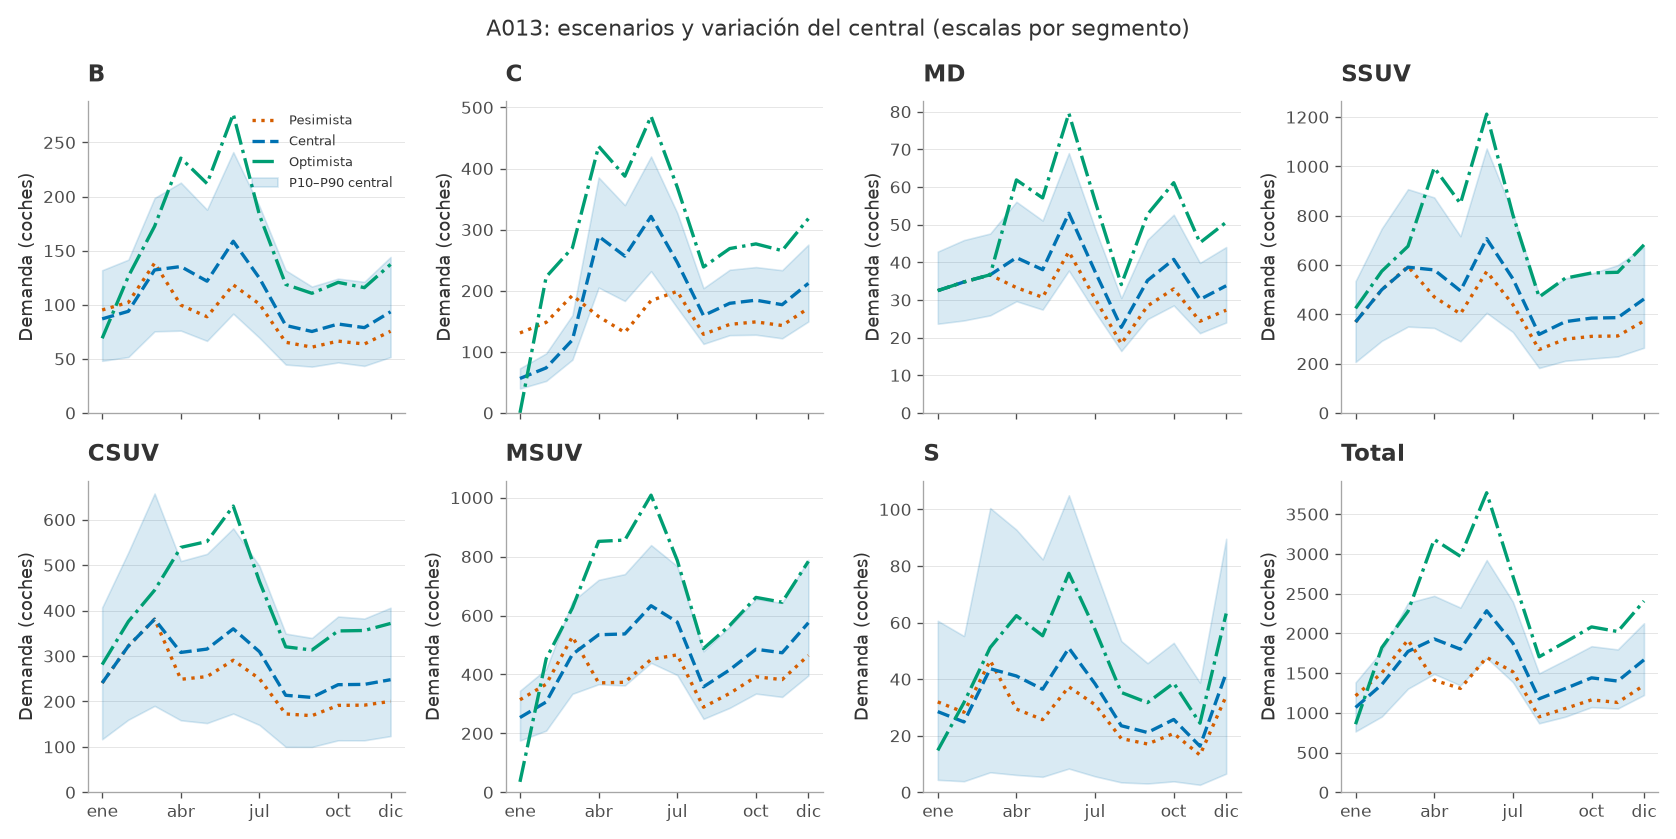

In [11]:
fig, ejes = plt.subplots(2, 4, figsize=(14, 7), sharex=True)
for eje, segmento in zip(ejes.flat, SEGMENTOS + ["Total"]):
    for nombre, color, estilo in [("pesimista", "#D55E00", ":"), ("central", "#0072B2", "--"), ("optimista", "#009E73", "-.")]:
        p = escenarios[nombre]
        valores = p[segmento] if segmento != "Total" else p.sum(axis=1)
        eje.plot(np.arange(1, 13), valores, color=color, linestyle=estilo, label=nombre.capitalize())
    g = distribucion[distribucion.segmento.eq(segmento)]
    eje.fill_between(np.arange(1, 13), g.p10.to_numpy(), g.p90.to_numpy(), color="#0072B2", alpha=.15, label="P10–P90 central")
    eje.set_title(segmento, loc="left")
    eje.set_ylabel("Demanda (coches)")
    eje.set_xticks([1, 4, 7, 10, 12], ["ene", "abr", "jul", "oct", "dic"])
    eje.set_ylim(bottom=0)
ejes.flat[0].legend(fontsize=8)
fig.suptitle("A013: escenarios y variación del central (escalas por segmento)")
fig.tight_layout()
guardar_figura(fig, "prevision_a013_ocho_paneles")


Fuente: datos hasta A012 y supuestos cuantificados en las tablas anteriores; 1.000 réplicas, semilla 42. Las líneas representan previsiones condicionadas y la banda sólo variación del central. La sensibilidad del lanzamiento y los meses con devolución truncada del ledger requieren seguimiento específico, no una promesa de precisión para toda la gama.

## Comprobaciones reproducibles del contrato y de ausencia de fugas

Se comprueban columnas, fechas, finitud, igualdad exacta del central y ledger común. Se alteran variables macro y sucesos posteriores al origen sin cambiar el calendario conocido; también se alteran ventas, mercado y renovación futuros para verificar el aislamiento del efecto producto. CSUV no aparece entre los errores validables y su dispersión es positiva por construcción proxy.

In [12]:
comprobaciones = []

def comprobar(nombre, condicion):
    assert bool(condicion), nombre
    comprobaciones.append({"comprobacion": nombre, "correcto": True})

comprobar("Fechas y segmentos contrato", base["prevision"].index.tolist() == list(range(145, 157)) and base["prevision"].columns.tolist() == SEGMENTOS)
comprobar("Proyecciones finitas y no negativas", all(np.isfinite(p.to_numpy()).all() and not p.lt(0).any().any() for p in escenarios.values()))
pd.testing.assert_frame_equal(escenarios["central"], base["prevision"])
comprobar("Central exactamente igual a la base", True)
comprobar("Selección A009-A011 exclusivamente", set(base["errores"].origen) == {96, 108, 120})
comprobar("CSUV excluido de errores validables", set(base["errores"].segmento) == set(VALIDABLES))
comprobar("CSUV proxy positivo", base["sd_log"]["CSUV"] > 0 and base["sigma3_rel"]["CSUV"] > 0)
comprobar("Rangos phi y rho", -.8 <= base["phi"] <= .8 and 0 <= base["rho"] <= .8)
neto = base["datos"]["ventas"].assign(neto=lambda d: d.unidades - d.u_automatriculacion).groupby(["t", "segmento"], observed=True)["neto"].sum().unstack().reindex(columns=SEGMENTOS)
pd.testing.assert_frame_equal(_pivotar(base["serie"], "demanda_observada"), neto, check_dtype=False, check_index_type=False, check_column_type=False)
comprobar("Target observado coincide con ventas netas fuente", True)
mercado = _mercado_completo(base["datos"])
cal = _calendario(base["datos"])
mutado = cal.copy()
mutado.loc[mutado.index > 96, MACRO + EVENTOS] = 999.0
for modelo in MODELOS[1:]:
    p0, _ = _prever_mercado(mercado, cal, 96, modelo)
    p1, _ = _prever_mercado(mercado, mutado, 96, modelo)
    pd.testing.assert_frame_equal(p0, p1)
comprobar("Economía y sucesos futuros no cambian forecast operativo", True)
p0, _ = _prever_mercado(mercado, cal, 96, "macro", condicionado=True)
p1, _ = _prever_mercado(mercado, mutado, 96, "macro", condicionado=True)
comprobar("Modo condicionado separado responde a información futura", not np.allclose(p0, p1))
serie_mutada = base["serie"].copy()
mascara = serie_mutada.t.gt(108)
serie_mutada.loc[mascara, ["demanda_observada", "mercado", "renovacion_gama"]] = 999.0
producto0, episodios0 = _producto(base["serie"], 108)
producto1, episodios1 = _producto(serie_mutada, 108)
pd.testing.assert_frame_equal(producto0, producto1)
pd.testing.assert_frame_equal(episodios0, episodios1)
comprobar("Producto ignora datos posteriores al origen", True)
for modelo in MODELOS:
    p0, _, _, _ = _prever(base["serie"], mercado, cal, 108, modelo)
    p1, _, _, _ = _prever(serie_mutada, mercado, cal, 108, modelo)
    pd.testing.assert_frame_equal(p0, p1)
comprobar("Ventas y producto futuros no cambian forecast operativo", True)
poison = base["serie"].copy()
poison["demanda_alternativa"] = 1e9
p0, _, _, _ = _prever(base["serie"], mercado, cal, 108, "macro")
p1, _, _, _ = _prever(poison, mercado, cal, 108, "macro")
pd.testing.assert_frame_equal(p0, p1)
comprobar("Target alternativo no contamina forecast principal", True)
normalizada, _, _, _ = _prever(base["serie"], mercado, cal, 144, "estacional", adelantos=base["_contexto"]["adelantos_completos"])
ancla = base["serie"][base["serie"].t.between(133, 144)].copy()
ancla["esperado"] = ancla.demanda_observada - ancla.ajuste_adelanto_mes + ancla.ajuste_caida_mes
esperado = _pivotar(ancla, "esperado")[VALIDABLES]
esperado.index += 12
pd.testing.assert_frame_equal(normalizada[VALIDABLES], esperado, check_dtype=False)
comprobar("Referencia estacional no repite pico A012", True)
comprobar("Ledger usa sólo A012 y coincide con saldo A013", set(base["adelantos"].anio) == {"A012"} and np.allclose(base["adelantos"].adelanto_central, base["adelantos"].saldo_para_siguiente_anio))
comprobar("Ledger solicitado común entre escenarios", np.allclose(ledger_escenarios.solicitado, ledger_escenarios.solicitado.iloc[0]))
comprobar("Duraciones pesimista/central/optimista 6/3/1", [base["_contexto"]["supuestos"][n]["duracion_ledger"] for n in escenarios] == [6, 3, 1])
ultimo = cal.loc[:144]
for variable in MACRO:
    sin_choque = prever_escenario_revision(base, "optimista", {"macroeconomia": {variable: [float(ultimo[variable].iloc[-1])] * 12}})
    comprobar(f"Factor {variable} interviene en escenario", not np.allclose(sin_choque, escenarios["optimista"]))
sin_ayuda = prever_escenario_revision(base, "optimista", {"supuestos": {"ayuda": 0.0}})
comprobar("Ayuda optimista interviene abr-dic", not np.allclose(sin_ayuda, escenarios["optimista"]))
sin_turismo = prever_escenario_revision(base, "optimista", {"supuestos": {"turismo": 0.0}})
comprobar("Turismo interviene sólo mar-jun", np.allclose(sin_turismo.loc[[145, 146, 151, 152, 153, 154, 155, 156]], escenarios["optimista"].loc[[145, 146, 151, 152, 153, 154, 155, 156]]) and not np.allclose(sin_turismo.loc[147:150], escenarios["optimista"].loc[147:150]))
sin_producto = prever_escenario_revision(base, "optimista", {"producto": {s: 0.0 for s in ["B", "SSUV", "CSUV", "MSUV"]}})
comprobar("Producto sólo altera segmentos renovados", np.allclose(sin_producto[["C", "MD", "S"]], escenarios["optimista"][["C", "MD", "S"]]) and not np.allclose(sin_producto[["B", "SSUV", "CSUV", "MSUV"]], escenarios["optimista"][["B", "SSUV", "CSUV", "MSUV"]]))
retraso_producto = prever_escenario_revision(base, "optimista", {"inicio_producto": {"MSUV": 148}})
comprobar("Sensibilidad retraso MSUV tres meses y duración seis", np.allclose(retraso_producto.loc[154:156], escenarios["optimista"].loc[154:156]) and not np.allclose(retraso_producto.loc[145:147, "MSUV"], escenarios["optimista"].loc[145:147, "MSUV"]))
bruto = base["errores_todos"].query("fase == 'seleccion_operativa' and modelo == @ganador")
factor0 = _factores_sesgo(bruto[bruto.origen.lt(120)])
bruto_mutado = bruto.copy()
bruto_mutado.loc[bruto_mutado.origen.eq(120), ["observado", "error"]] = 1e8
factor1 = _factores_sesgo(bruto_mutado[bruto_mutado.origen.lt(120)])
pd.testing.assert_series_equal(factor0, factor1)
comprobar("Parámetro de sesgo A011 no usa error de A011", True)
mostrar_tabla(pd.DataFrame(comprobaciones), "comprobaciones_demanda")
print(f"{len(comprobaciones)} comprobaciones correctas; API sin argumentos ejecutada al inicio.")


,comprobacion,correcto
0,Fechas y segmentos contrato,True
1,Proyecciones finitas y no negativas,True
2,Central exactamente igual a la base,True
3,Selección A009-A011 exclusivamente,True
4,CSUV excluido de errores validables,True
5,CSUV proxy positivo,True
6,Rangos phi y rho,True
7,Target observado coincide con ventas netas fuente,True
8,Economía y sucesos futuros no cambian forecast...,True
9,Modo condicionado separado responde a informac...,True


25 comprobaciones correctas; API sin argumentos ejecutada al inicio.


## Límites y seguimiento

La evaluación identifica el candidato con menor error entre cuatro alternativas, no un modelo universalmente fiable. El lanzamiento CSUV, las compras adelantadas y el producto siguen siendo supuestos poco identificados: deben contrastarse con las primeras ventas A013, diferenciando una señal de stock de una caída de clientes. La simulación logística debe consumir esta única API y conservar las sensibilidades, sin reintroducir sucesos de caída ni otro descuento del ledger.